# CropSense: Computer Recognition of Observed Plant Stress

ResNet18 transfer learning on 9 PlantVillage classes (tomato, potato, bell pepper), then a prototypical network so new diseases can be added from 5-10 photos with no retraining.

Built in Google Colab. Paths like `/content/drive/MyDrive/...` point to my Google Drive; change them to your own.

In [ ]:
!git clone https://github.com/spMohanty/PlantVillage-Dataset.git


Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 163264, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 163264 (delta 16), reused 25 (delta 9), pack-reused 163229 (from 1)
Receiving objects: 100% (163264/163264), 2.00 GiB | 24.76 MiB/s, done.
Resolving deltas: 100% (115/115), done.
Updating files: 100% (182404/182404), done.


In [ ]:
import os
import shutil
from pathlib import Path

# Define paths and parameters
base_raw = "PlantVillage-Dataset/raw/color"
out_balanced = "dataset_balanced"
MIN_IMAGES = 150

KEEP_CLASSES = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Potato___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Pepper,_bell___healthy",
    "Pepper,_bell___Bacterial_spot"
]


if Path(out_balanced).exists():
    shutil.rmtree(out_balanced)
Path(out_balanced).mkdir(exist_ok=True)

print(f"Creating balanced dataset in: {out_balanced}")
print(f"Keeping {MIN_IMAGES} images per class for the following classes:")
for cls in KEEP_CLASSES:
    print(f"- {cls}")

copied_counts = {}

for folder_name in os.listdir(base_raw):
    src_class_path = os.path.join(base_raw, folder_name)

    if os.path.isdir(src_class_path) and folder_name in KEEP_CLASSES:
        dst_class_path = os.path.join(out_balanced, folder_name)
        Path(dst_class_path).mkdir(parents=True, exist_ok=True)

        images_in_src = [f for f in os.listdir(src_class_path) if os.path.isfile(os.path.join(src_class_path, f))]
        copied_count = 0
        for img_name in images_in_src:
            if copied_count >= MIN_IMAGES:
                break
            shutil.copy(os.path.join(src_class_path, img_name), dst_class_path)
            copied_count += 1
        copied_counts[folder_name] = copied_count
        print(f"Copied {copied_count} images for class: {folder_name}")

print("\nFinal counts in dataset_balanced:")
for cls in KEEP_CLASSES:
    count = copied_counts.get(cls, 0)
    print(f"- {cls}: {count}")

Creating balanced dataset in: dataset_balanced
Keeping 150 images per class for the following classes:
- Tomato___healthy
- Tomato___Early_blight
- Tomato___Late_blight
- Tomato___Tomato_Yellow_Leaf_Curl_Virus
- Potato___healthy
- Potato___Early_blight
- Potato___Late_blight
- Pepper,_bell___healthy
- Pepper,_bell___Bacterial_spot
Copied 150 images for class: Potato___Late_blight
Copied 150 images for class: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Copied 150 images for class: Pepper,_bell___healthy
Copied 150 images for class: Tomato___Early_blight
Copied 150 images for class: Potato___healthy
Copied 150 images for class: Tomato___Late_blight
Copied 150 images for class: Tomato___healthy
Copied 150 images for class: Pepper,_bell___Bacterial_spot
Copied 150 images for class: Potato___Early_blight

Final counts in dataset_balanced:
- Tomato___healthy: 150
- Tomato___Early_blight: 150
- Tomato___Late_blight: 150
- Tomato___Tomato_Yellow_Leaf_Curl_Virus: 150
- Potato___healthy: 150
- Potato

In [ ]:
import torch
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, random_split
import torch.nn as nn
import torch.optim as optim

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.10.0+cpu
CUDA available: False


In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


dataset = datasets.ImageFolder(
    root="dataset_balanced",
    transform=transform
)

num_classes = len(dataset.classes)
print("Classes:", dataset.classes)
print("Number of classes:", num_classes)


Classes: ['Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___healthy']
Number of classes: 9


TRAINING STAGE -- ONLY RUN IF YOU WANT TO RETRAIN THE MODEL

In [ ]:
from torch.utils.data import DataLoader, random_split

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_ds, val_ds = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)

print("Train samples:", len(train_ds))
print("Validation samples:", len(val_ds))


Train samples: 1080
Validation samples: 270


In [ ]:
import torch
import torch.nn as nn
import torchvision

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = torchvision.models.resnet18(pretrained=True)

for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)


Using device: cpu


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)


In [ ]:
train_losses = []
train_accuracies = []
val_accuracies = []

EPOCHS = 10

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = 100 * correct / total
    avg_loss = running_loss / len(train_loader)

    # Calculate validation accuracy for the current epoch
    model.eval()
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_acc = 100 * val_correct / val_total

    train_losses.append(avg_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(epoch_val_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {avg_loss:.4f} | Train Acc: {train_acc:.2f}% | Val Acc: {epoch_val_acc:.2f}%")


Epoch 1/10 | Loss: 1.8440 | Train Acc: 36.76% | Val Acc: 69.63%
Epoch 2/10 | Loss: 1.0821 | Train Acc: 77.59% | Val Acc: 84.07%
Epoch 3/10 | Loss: 0.7500 | Train Acc: 85.83% | Val Acc: 89.63%
Epoch 4/10 | Loss: 0.5962 | Train Acc: 88.43% | Val Acc: 92.59%
Epoch 5/10 | Loss: 0.5008 | Train Acc: 90.74% | Val Acc: 91.48%
Epoch 6/10 | Loss: 0.4245 | Train Acc: 91.11% | Val Acc: 90.74%
Epoch 7/10 | Loss: 0.3705 | Train Acc: 92.69% | Val Acc: 94.44%
Epoch 8/10 | Loss: 0.3426 | Train Acc: 92.87% | Val Acc: 90.37%
Epoch 9/10 | Loss: 0.2985 | Train Acc: 93.70% | Val Acc: 90.74%
Epoch 10/10 | Loss: 0.2994 | Train Acc: 93.98% | Val Acc: 94.81%


# Meta Learning Model

The original model memorised 9 specific disease. Meta-learning allows it to recognize new diseases it's never seen before, simply by comparing a few example photos.

What this does:

The prior model used to do 2 things:  
1. Look at the leaf and extract features
2. Classify those features into one of 9 diseases

Following cell removes the classification part, and keeps the 512 list of numbers. Represents something like a fingerprint for the leaf image. This fingerprint is the **embedding**

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models
from torchvision import transforms
from PIL import Image
import numpy as np
import os

class EmbeddingNet(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        # Remove the final classification layer
        self.encoder = nn.Sequential(*list(backbone.children())[:-1])

    def forward(self, x):
        x = self.encoder(x)
        return x.view(x.size(0), -1)  # flatten to (batch, 512)

num_classes = 9
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

backbone = models.resnet18(pretrained=False)
backbone.fc = nn.Linear(backbone.fc.in_features, num_classes)
backbone.load_state_dict(torch.load('/content/drive/MyDrive/resnet18_plant_disease_classifier.pth',
                                     map_location=device))
backbone = backbone.to(device)

embedding_net = EmbeddingNet(backbone).to(device)
embedding_net.eval()

print("Embedding network ready. Output size: 512")


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Embedding network ready. Output size: 512


Prototype Store creates a dictionary that stores the "average fingerprint" per disease class. This is known as the prototype, and it can be thought of as the centre of gravity for what that disease would look like in a 512-dimensional space.

Add class produces a prototype based on 5-10 support images.

Predict gets the fingerprint for that unknown leaf image, measures how far that fingerprint is from every prototype stored. The closest one is the models prediction, computed using Euclidean distance (distance formula in 512 dimensions)

In [ ]:
class PrototypeStore:
    def __init__(self, embedding_net, device):
        self.net = embedding_net
        self.device = device
        self.prototypes = {}   # class_name -> mean embedding tensor
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225])
        ])

    def add_class(self, class_name, image_paths):
        """Register a new class using a handful of support images."""
        embeddings = []
        self.net.eval()
        with torch.no_grad():
            for path in image_paths:
                img = Image.open(path).convert('RGB')
                tensor = self.transform(img).unsqueeze(0).to(self.device)
                emb = self.net(tensor)
                embeddings.append(emb)
        # Prototype = mean of all support embeddings
        prototype = torch.stack(embeddings).mean(dim=0)
        self.prototypes[class_name] = prototype
        print(f"Registered prototype for: {class_name} ({len(image_paths)} images)")

    def predict(self, image_path):
        """Classify a query image by nearest prototype."""
        self.net.eval()
        with torch.no_grad():
            img = Image.open(image_path).convert('RGB')
            tensor = self.transform(img).unsqueeze(0).to(self.device)
            query_emb = self.net(tensor)

        # Compute Euclidean distance to every prototype
        distances = {}
        for class_name, proto in self.prototypes.items():
            dist = torch.dist(query_emb, proto).item()
            distances[class_name] = dist

        # Nearest prototype wins
        predicted = min(distances, key=distances.get)
        # Convert distances to confidence scores via softmax
        dist_tensor = torch.tensor(list(distances.values()))
        scores = torch.softmax(-dist_tensor, dim=0)
        confidence = {k: round(v.item(), 3)
                      for k, v in zip(distances.keys(), scores)}

        return predicted, confidence

store = PrototypeStore(embedding_net, device)

Registers the 9 original diseases into the prototype store using an average of 10 embeddings per image. The model now knows how the 9 diseases look like in embedding space.

In [ ]:
from torch.utils.data import random_split

# Ensure the dataset is loaded first
# (This assumes you've already run the datasets.ImageFolder cell)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

# This creates the val_ds variable the Prototype Store is looking for
train_ds, val_ds = random_split(dataset, [train_size, val_size])

print(f"Dataset split successfully. Validation set size: {len(val_ds)}")

Dataset split successfully. Validation set size: 270


In [ ]:
from torch.utils.data import Subset

store_populated = False

# Group val images by class
class_to_paths = {cls: [] for cls in dataset.classes}
for idx in val_ds.indices:
    path, label = dataset.samples[idx]
    class_to_paths[dataset.classes[label]].append(path)

# Register each class using up to 10 support images
for cls_name, paths in class_to_paths.items():
    support_paths = paths[:10]
    store.add_class(cls_name, support_paths)

store_populated = True
print(f"\nPrototype store ready with {len(store.prototypes)} classes.")

Registered prototype for: Pepper,_bell___Bacterial_spot (10 images)
Registered prototype for: Pepper,_bell___healthy (10 images)
Registered prototype for: Potato___Early_blight (10 images)
Registered prototype for: Potato___Late_blight (10 images)
Registered prototype for: Potato___healthy (10 images)
Registered prototype for: Tomato___Early_blight (10 images)
Registered prototype for: Tomato___Late_blight (10 images)
Registered prototype for: Tomato___Tomato_Yellow_Leaf_Curl_Virus (10 images)
Registered prototype for: Tomato___healthy (10 images)

Prototype store ready with 9 classes.


This is where the magic happens. By simply inputting 5-10 images of a drought-stressed / infected plant, it instantly becomes a 10th class the model can predict.

This makes it useful for real world farmers, where a field agent could photograph 5 examples of a new local disease and add it to the system.

Diagnose is a friendly wrapper to present the result visually.

In [ ]:
def register_new_disease(class_name, folder_path, n_support=5):
    """
    Register a brand-new disease class from a folder of images.
    You only need n_support images — no retraining needed.
    """
    image_paths = [
        os.path.join(folder_path, f)
        for f in os.listdir(folder_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ][:n_support]

    if len(image_paths) < n_support:
        print(f"Warning: only found {len(image_paths)} images (wanted {n_support})")

    store.add_class(class_name, image_paths)
    print(f"New class '{class_name}' added. Total classes: {len(store.prototypes)}")

In [ ]:
def diagnose(image_path):
    predicted, confidence = store.predict(image_path)
    print(f"\nDiagnosis: {predicted}")
    print("Confidence scores:")
    for cls, score in sorted(confidence.items(), key=lambda x: -x[1]):
        bar = '█' * int(score * 30)
        print(f"  {cls:<45} {bar} {score:.1%}")

In [ ]:
register_new_disease('powdery_mildew', '/content/drive/MyDrive/MoldyCheese')

Registered prototype for: powdery_mildew (5 images)
New class 'powdery_mildew' added. Total classes: 10


In [ ]:
diagnose('/content/powdery2.jpg')


Diagnosis: powdery_mildew
Confidence scores:
  powdery_mildew                                ████████████████████████ 82.5%
  Tomato___Late_blight                          █ 4.1%
  Tomato___Tomato_Yellow_Leaf_Curl_Virus        █ 3.4%
  Tomato___Early_blight                          3.0%
  Potato___Early_blight                          2.6%
  Potato___Late_blight                           1.2%
  Pepper,_bell___Bacterial_spot                  1.0%
  Potato___healthy                               1.0%
  Pepper,_bell___healthy                         0.6%
  Tomato___healthy                               0.6%


In [ ]:
register_new_disease('BlackKnot', '/content/drive/MyDrive/BlackKnot')

Registered prototype for: BlackKnot (5 images)
New class 'BlackKnot' added. Total classes: 11


In [ ]:
diagnose('/content/BlackKnot7')


Diagnosis: BlackKnot
Confidence scores:
  BlackKnot                                     ███████████████████████████ 90.8%
  powdery_mildew                                █ 4.6%
  Tomato___Tomato_Yellow_Leaf_Curl_Virus         1.1%
  Tomato___Early_blight                          0.9%
  Tomato___Late_blight                           0.9%
  Potato___Early_blight                          0.6%
  Tomato___healthy                               0.4%
  Pepper,_bell___Bacterial_spot                  0.2%
  Potato___Late_blight                           0.2%
  Pepper,_bell___healthy                         0.1%
  Potato___healthy                               0.1%


In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# ── Step 1: Make sure store is populated with all 9 classes ──
# (Run the prototype store population cells first if not done)
assert store_populated, "Run the prototype store population cells first"
assert len(store.prototypes) == 9, f"Expected 9 prototypes, got {len(store.prototypes)}"
print(f"Prototype store has {len(store.prototypes)} classes. Ready to evaluate.")

AssertionError: Expected 9 prototypes, got 10

In [ ]:
# ── Step 2: Run prototypical network on every val image ──

proto_true = []
proto_pred = []

# Map class name -> index (same ordering as dataset.classes)
class_to_idx = {cls: i for i, cls in enumerate(dataset.classes)}

print("Running prototypical network on validation set...")
for idx in val_ds.indices:
    path, true_label = dataset.samples[idx]

    try:
        predicted_class, _ = store.predict(path)
        pred_label = class_to_idx[predicted_class]
    except Exception as e:
        # If prediction fails, mark as wrong
        pred_label = -1

    proto_true.append(true_label)
    proto_pred.append(pred_label)

proto_true = np.array(proto_true)
proto_pred = np.array(proto_pred)

proto_accuracy = 100 * np.mean(proto_true == proto_pred)
print(f"\nPrototypical Network Accuracy: {proto_accuracy:.2f}%")
val_acc = 94.53
print(f"Original Classifier Accuracy:  {val_acc:.2f}%")
print(f"Difference: {proto_accuracy - val_acc:+.2f}%")

Running prototypical network on validation set...

Prototypical Network Accuracy: 88.52%
Original Classifier Accuracy:  94.53%
Difference: -6.01%


In [ ]:
# ── Step 3: Per-class accuracy comparison ──

print("\nPer-class accuracy comparison:")
print(f"{'Class':<45} {'Original':>10} {'Proto Net':>10} {'Diff':>8}")
print("─" * 75)

proto_per_class = []
original_per_class = []

for i, cls in enumerate(dataset.classes):
    mask = proto_true == i
    if mask.sum() == 0:
        proto_acc_cls = 0.0
    else:
        proto_acc_cls = 100 * np.mean(proto_pred[mask] == i)

    # Get original per-class accuracy from earlier computation
    orig_acc_cls = per_class_accuracy[i]

    proto_per_class.append(proto_acc_cls)
    original_per_class.append(orig_acc_cls)

    diff = proto_acc_cls - orig_acc_cls
    marker = " ▲" if diff > 0 else (" ▼" if diff < 0 else "  ")
    print(f"{cls:<45} {orig_acc_cls:>9.1f}% {proto_acc_cls:>9.1f}% {diff:>+7.1f}%{marker}")


Per-class accuracy comparison:
Class                                           Original  Proto Net     Diff
───────────────────────────────────────────────────────────────────────────
Pepper,_bell___Bacterial_spot                     100.0%      95.5%    -4.5% ▼
Pepper,_bell___healthy                            100.0%      96.2%    -3.8% ▼
Potato___Early_blight                              94.1%      91.4%    -2.7% ▼
Potato___Late_blight                               96.2%      88.9%    -7.3% ▼
Potato___healthy                                  100.0%      96.8%    -3.2% ▼
Tomato___Early_blight                              85.0%      81.2%    -3.8% ▼
Tomato___Late_blight                               86.1%      67.7%   -18.4% ▼
Tomato___Tomato_Yellow_Leaf_Curl_Virus            100.0%      96.6%    -3.4% ▼
Tomato___healthy                                  100.0%      85.7%   -14.3% ▼


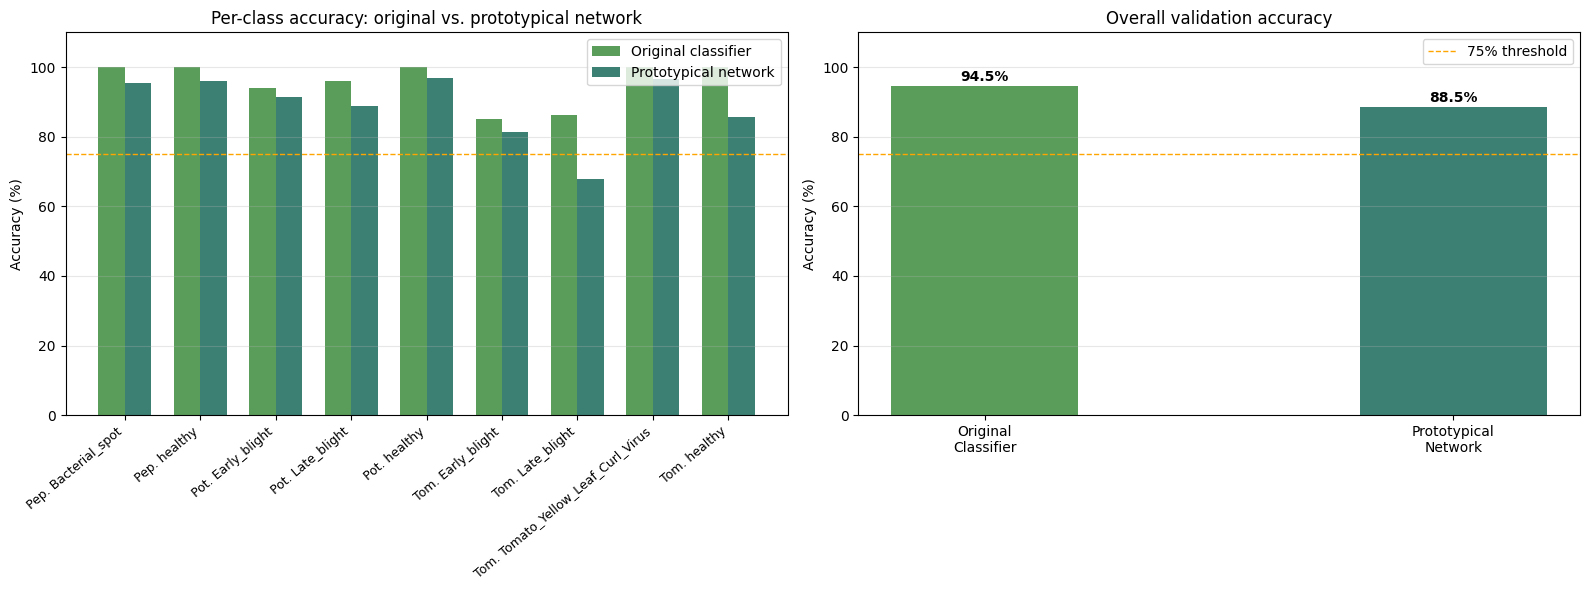

Saved: meta_learning_comparison.png


In [ ]:
# ── Step 4: Side-by-side bar chart ──

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
short_names = [c.replace('Tomato___', 'Tom. ').replace('Potato___', 'Pot. ')
                .replace('Pepper,_bell___', 'Pep. ') for c in dataset.classes]
x = np.arange(len(dataset.classes))
w = 0.35

axes[0].bar(x - w/2, original_per_class, w, label='Original classifier',
            color='#3d8c3d', alpha=0.85)
axes[0].bar(x + w/2, proto_per_class, w, label='Prototypical network',
            color='#1a6a5c', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(short_names, rotation=40, ha='right', fontsize=9)
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim(0, 110)
axes[0].set_title('Per-class accuracy: original vs. prototypical network')
axes[0].legend()
axes[0].axhline(75, color='orange', linestyle='--', linewidth=1, label='75% threshold')
axes[0].grid(axis='y', alpha=0.3)

# Overall accuracy bars
axes[1].bar(['Original\nClassifier', 'Prototypical\nNetwork'],
            [val_acc, proto_accuracy],
            color=['#3d8c3d', '#1a6a5c'], alpha=0.85, width=0.4)
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_ylim(0, 110)
axes[1].set_title('Overall validation accuracy')
axes[1].axhline(75, color='orange', linestyle='--', linewidth=1, label='75% threshold')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)
for i, v in enumerate([val_acc, proto_accuracy]):
    axes[1].text(i, v + 1.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('meta_learning_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: meta_learning_comparison.png")

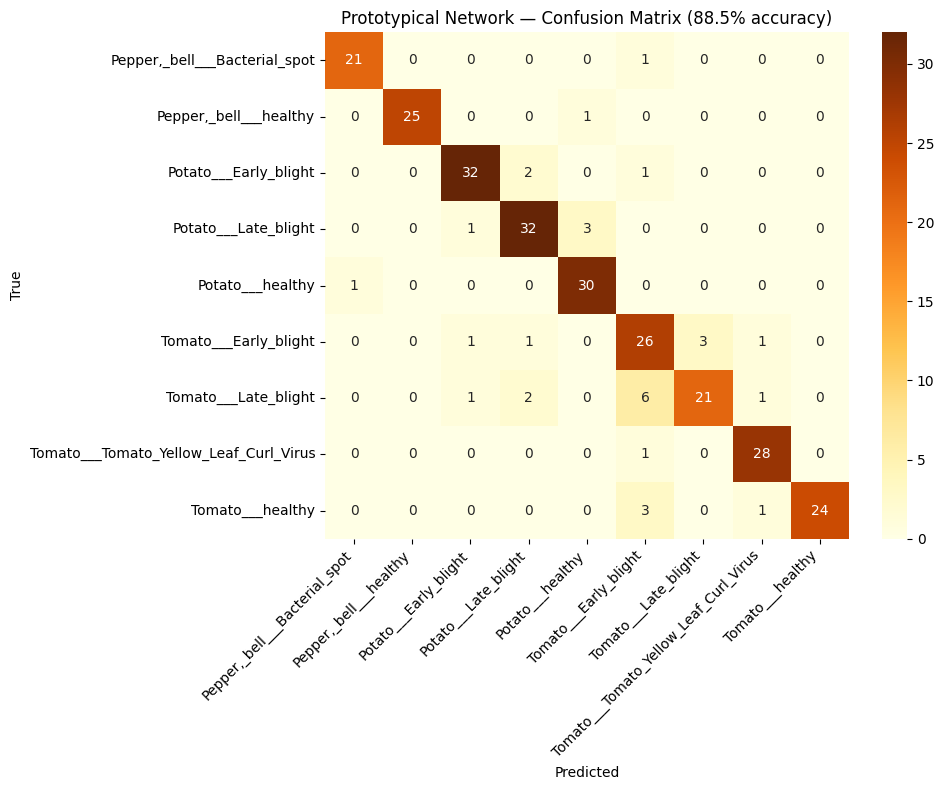

In [ ]:
# ── Step 5: Confusion matrix for prototypical network ──

proto_cm = confusion_matrix(proto_true, proto_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(proto_cm, annot=True, fmt='g', cmap='YlOrBr',
            xticklabels=dataset.classes,
            yticklabels=dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Prototypical Network — Confusion Matrix ({proto_accuracy:.1f}% accuracy)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('proto_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

Template for adding new diseases

In [ ]:
register_new_disease('Dehydrated_Plant', '/content/drive/MyDrive/Dehydrated_Plant')

Registered prototype for: Dehydrated_Plant (5 images)
New class 'Dehydrated_Plant' added. Total classes: 10


In [ ]:
diagnose('/content/drive/MyDrive/Dehydrated_Plant/Screenshot 2026-03-23 at 10.07.09 AM.png')


Diagnosis: Tomato___Early_blight
Confidence scores:
  Tomato___Early_blight                         ███████ 25.4%
  Dehydrated_Plant                              ██████ 20.2%
  Tomato___Late_blight                          █████ 17.4%
  Potato___Early_blight                         ███ 12.6%
  Potato___Late_blight                          █ 5.9%
  Pepper,_bell___healthy                        █ 5.7%
  Tomato___Tomato_Yellow_Leaf_Curl_Virus        █ 5.7%
  Pepper,_bell___Bacterial_spot                 █ 4.8%
  Tomato___healthy                               1.3%
  Potato___healthy                               1.0%


In [ ]:
diagnose('/content/Screenshot 2026-03-23 at 10.16.20 AM.png')


Diagnosis: Dehydrated_Plant
Confidence scores:
  Dehydrated_Plant                              ████████████████████████████ 94.3%
  Tomato___Early_blight                          1.2%
  Tomato___Late_blight                           1.1%
  Tomato___Tomato_Yellow_Leaf_Curl_Virus         0.9%
  Pepper,_bell___Bacterial_spot                  0.7%
  Pepper,_bell___healthy                         0.5%
  Potato___Late_blight                           0.4%
  Potato___healthy                               0.4%
  Potato___Early_blight                          0.3%
  Tomato___healthy                               0.2%


In [ ]:
diagnose('/content/Screenshot 2026-03-23 at 10.29.07 AM.png')


Diagnosis: Dehydrated_Plant
Confidence scores:
  Dehydrated_Plant                              ████████████ 42.7%
  Tomato___Tomato_Yellow_Leaf_Curl_Virus        ███ 12.5%
  Tomato___Early_blight                         ███ 11.3%
  Tomato___Late_blight                          ██ 9.8%
  Potato___Late_blight                          ██ 7.0%
  Pepper,_bell___healthy                        █ 5.8%
  Pepper,_bell___Bacterial_spot                 █ 4.1%
  Potato___Early_blight                         █ 3.5%
  Tomato___healthy                               1.9%
  Potato___healthy                               1.5%


In [ ]:
torch.save(store.prototypes, 'prototypes.pt')

Note: the prototype store only lives in memory. Use torch.save(store.prototypes, 'prototypes.pt') to reload it later.

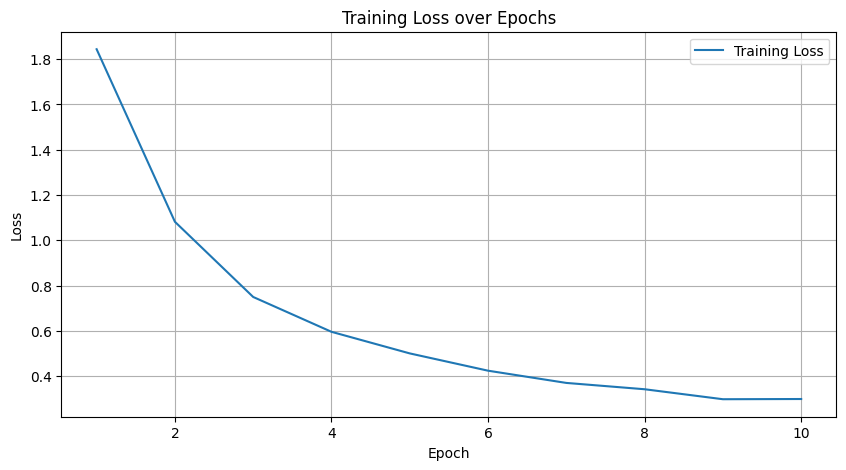

Generated plot for training loss.


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(range(1, EPOCHS + 1), train_losses, label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs')
plt.legend()
plt.grid(True)
plt.show()
print("Generated plot for training loss.")

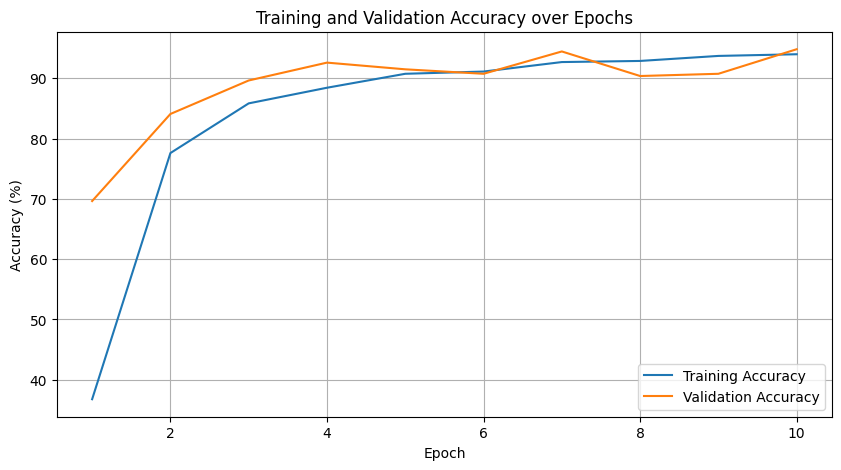

Generated plot for training and validation accuracy.


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(range(1, EPOCHS + 1), train_accuracies, label='Training Accuracy')
plt.plot(range(1, EPOCHS + 1), val_accuracies, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training and Validation Accuracy over Epochs')
plt.legend()
plt.grid(True)
plt.show()
print("Generated plot for training and validation accuracy.")

In [ ]:
model = backbone

## Calculate Predictions and True Labels



In [ ]:
true_labels = []
predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        true_labels.extend(labels.cpu().numpy())
        predictions.extend(predicted.cpu().numpy())

true_labels = torch.tensor(true_labels)
predictions = torch.tensor(predictions)

print("Collected true labels and predictions from the validation set.")

Collected true labels and predictions from the validation set.


In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Overall accuracies (already computed in previous steps)
print(f"Overall Validation Accuracy: {val_acc:.2f}%")

# Calculate per-class accuracy
class_correct = list(0. for i in range(num_classes))
class_total = list(0. for i in range(num_classes))

for i in range(len(true_labels)):
    label = true_labels[i]
    prediction = predictions[i]
    if label == prediction:
        class_correct[label] += 1
    class_total[label] += 1

per_class_accuracy = []
print("\nPer-class accuracy:")
for i in range(num_classes):
    if class_total[i] > 0:
        accuracy = 100 * class_correct[i] / class_total[i]
        per_class_accuracy.append(accuracy)
        print(f"  Class {dataset.classes[i]}: {accuracy:.2f}%")
    else:
        per_class_accuracy.append(0.0)
        print(f"  Class {dataset.classes[i]}: No samples in validation set.")



Overall Validation Accuracy: 94.53%

Per-class accuracy:
  Class Pepper,_bell___Bacterial_spot: 100.00%
  Class Pepper,_bell___healthy: 100.00%
  Class Potato___Early_blight: 94.12%
  Class Potato___Late_blight: 96.15%
  Class Potato___healthy: 100.00%
  Class Tomato___Early_blight: 85.00%
  Class Tomato___Late_blight: 86.11%
  Class Tomato___Tomato_Yellow_Leaf_Curl_Virus: 100.00%
  Class Tomato___healthy: 100.00%


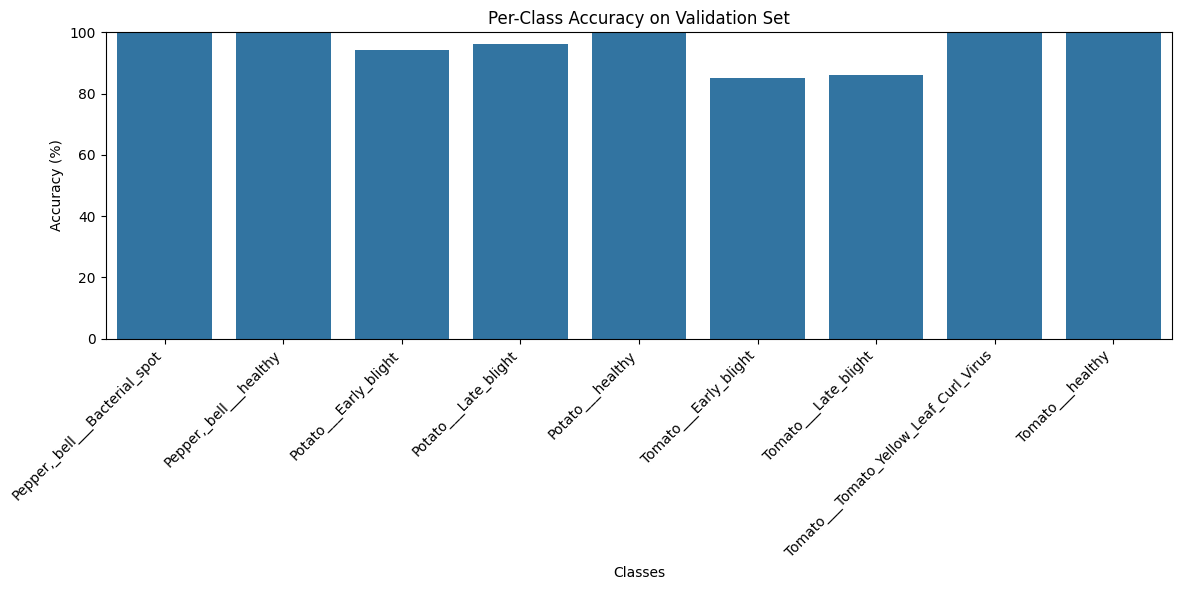

Generated bar chart for per-class accuracy.


In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(x=dataset.classes, y=per_class_accuracy)
plt.xlabel("Classes")
plt.ylabel("Accuracy (%)")
plt.title("Per-Class Accuracy on Validation Set")
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()
print("Generated bar chart for per-class accuracy.")

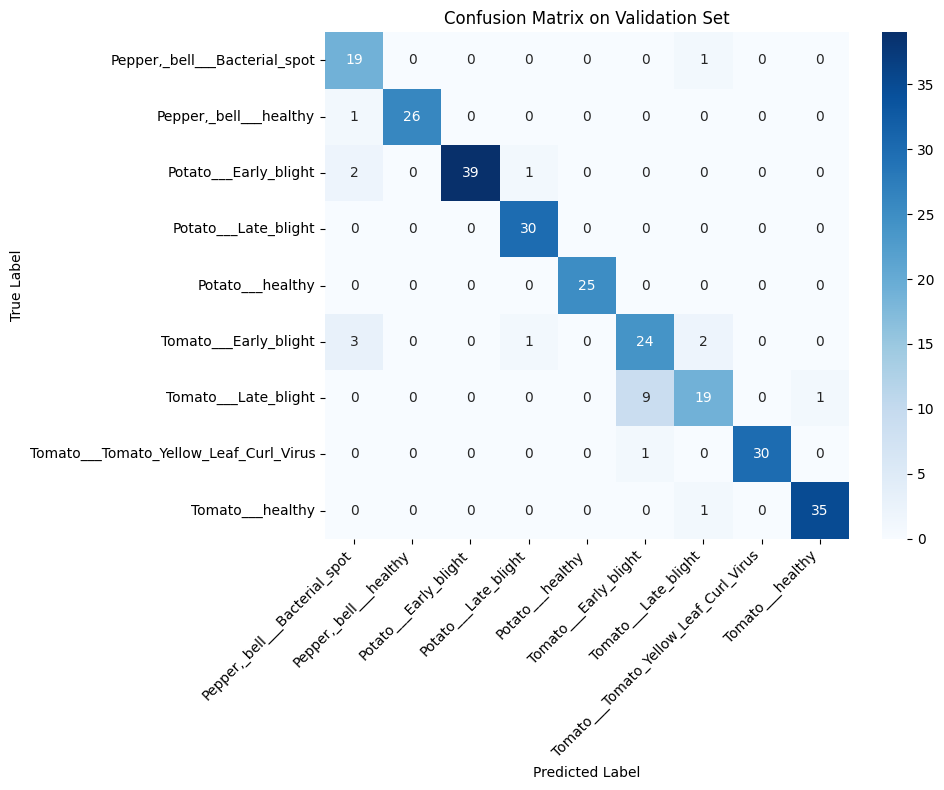

Generated confusion matrix heatmap.


In [ ]:
cm = confusion_matrix(true_labels, predictions)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues',
            xticklabels=dataset.classes,
            yticklabels=dataset.classes)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix on Validation Set')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
print("Generated confusion matrix heatmap.")

In [ ]:
import torch

# Define a path to save the model
model_save_path = 'resnet18_plant_disease_classifier.pth'

# Save the model's state_dict
torch.save(model.state_dict(), model_save_path)

print(f"Model state saved successfully to {model_save_path}")

Model state saved successfully to resnet18_plant_disease_classifier.pth


## Testing on real-world samples

## Testing the Model on New Images

To test the trained model on a new, real-world image, we need to perform the following steps:

1.  **Load the image**: Read the image file.
2.  **Preprocess the image**: Apply the same transformations (resize, normalize, convert to tensor) that were used for the training data.
3.  **Make a prediction**: Pass the preprocessed image through the loaded model.
4.  **Interpret the prediction**: Convert the model's output (logits) into a human-readable class label.

Let's define a function to handle the preprocessing and prediction.

In [ ]:
import torch
import torchvision.models as models
import torch.nn as nn

# We know the number of classes from previous training steps (cell lS-nQb7K3KoM)
num_classes = 9
print(f"Number of classes set to: {num_classes}")

# Re-instantiate the ResNet18 model architecture
model = models.resnet18(pretrained=False) # Load without pretrained weights
model.fc = nn.Linear(model.fc.in_features, num_classes) # Adjust the final layer with known num_classes

# Load the saved state_dict into the model
model_save_path = '/resnet18_plant_disease_classifier.pth'
state_dict = torch.load(model_save_path, map_location=torch.device('cpu')) # Load to CPU first
model.load_state_dict(state_dict)

# Move the model to the correct device (cpu or cuda)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Set the model to evaluation mode
model.eval()

print("Model loaded successfully and set to evaluation mode.")

Number of classes set to: 9
Model loaded successfully and set to evaluation mode.


In [ ]:
from PIL import Image
import torchvision.transforms as transforms
import torch

model.eval()

def preprocess_image(image_path):
    preprocess = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    image = Image.open(image_path).convert('RGB')
    image = preprocess(image).unsqueeze(0)
    return image

def predict_image(image_tensor, model, class_names):
    with torch.no_grad():
        output = model(image_tensor.to(device))
        probabilities = torch.nn.functional.softmax(output, dim=1)
        _, predicted_idx = torch.max(probabilities, 1)
        predicted_class = class_names[predicted_idx.item()]
    return predicted_class, probabilities[0][predicted_idx.item()].item()

print("Image preprocessing and prediction functions defined.")

Image preprocessing and prediction functions defined.


In [ ]:
# Replace 'your_image.jpg' with the path to your uploaded image file
test_image_path = '/content/Screenshot 2026-01-06 at 11.55.09 AM.png' # Example: '/content/test_leaf.jpg'

# Define KEEP_CLASSES here to make the cell self-contained
KEEP_CLASSES = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Potato___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Pepper,_bell___healthy",
    "Pepper,_bell___Bacterial_spot"
]

# Sort the KEEP_CLASSES list alphabetically to match ImageFolder's internal ordering
class_names = sorted(KEEP_CLASSES)

# Preprocess the image
input_image = preprocess_image(test_image_path)

# Make a prediction
predicted_class, confidence = predict_image(input_image, model, class_names)

print(f"The model predicts: {predicted_class} with a confidence of {confidence:.2f}")

The model predicts: Tomato___Tomato_Yellow_Leaf_Curl_Virus with a confidence of 0.28
